Torch version 2.8.0 has not been tested with coremltools. You may run into unexpected errors. Torch 2.7.0 is the most recent version that has been tested.


2/6: Loading CoreML model and detecting trees on ExG-segmented image...
Detected 47 valid trees; filtered out 0 undersized and 0 oversized detections.
3/6: Calculating VARI map and tree-level statistics...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
4/6: Grouping trees into 3x

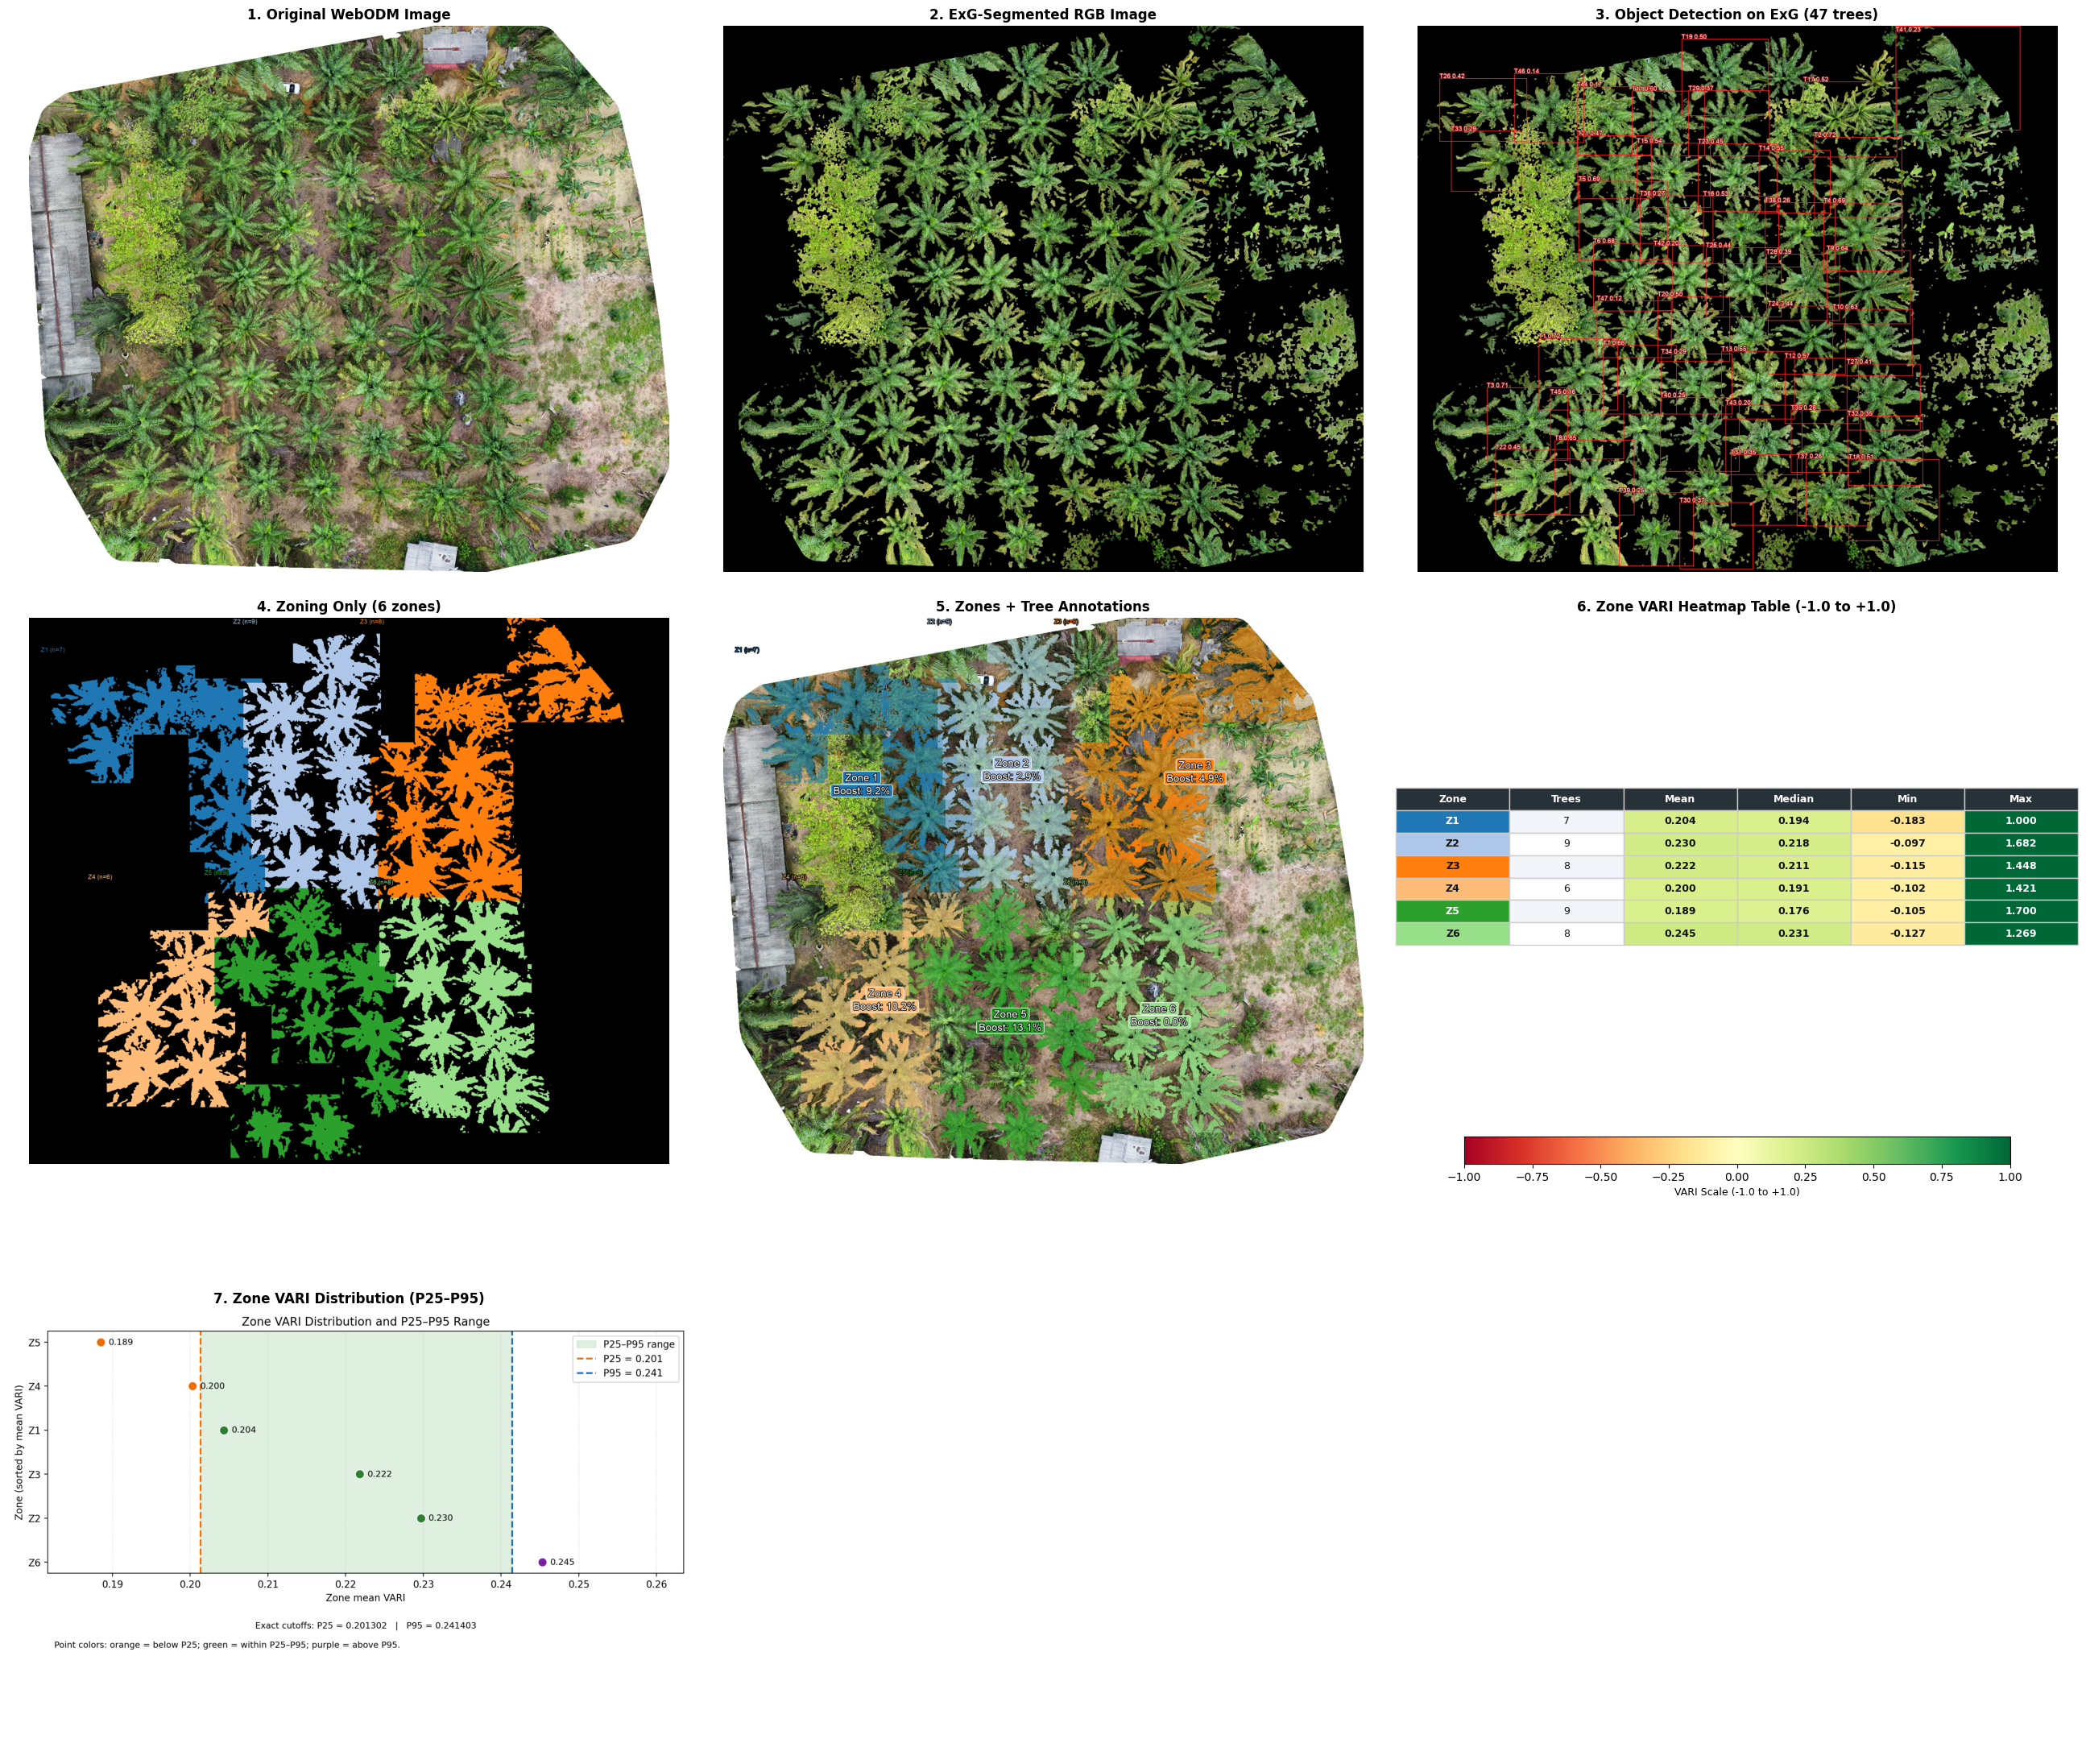

In [ ]:
"""Oil-palm zoning + VARI analysis for a WebODM RGB image.
Pipeline:
1. ExG vegetation segmentation
2. CoreML object detection on the ExG-segmented image
3. Spatial grouping of detections into zones containing up to N trees
4. Annotated images for each stage (ExG RGB, CoreML on ExG, and Zones on Original)
5. VARI statistics per tree and per zone, using ExG vegetation pixels
6. JSON and CSV export with pixel and normalized coordinates
Run on macOS with coremltools and the required model installed.
"""
import csv
import json
from pathlib import Path
import coremltools as ct
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFont
 # ------------------------- Configuration -------------------------
IMAGE_PATH = "webodm_new_2nd_flight.jpeg"  # Input RGB image to segment, detect palms, calculate VARI, and zone.
MODEL_PATH = "krops_model_v0.2_yolo26l.mlpackage"  # CoreML object-detection model used to detect palm trees.
OUTPUT_JSON = "oil_palm_zones_vari.json"  # JSON with metadata, zone/tree statistics, and recommendations.
OUTPUT_ZONE_CSV = "oil_palm_zone_vari_summary.csv"  # CSV with one row per zone and its VARI/fertilizer values.
OUTPUT_PRODUCT_MASS_CSV = "oil_palm_zone_fertilizer_product_mass.csv"  # CSV converting elemental nutrient totals to product mass.
OUTPUT_EXG_MASK = "oil_palm_exg_mask.png"  # Binary vegetation mask produced by ExG thresholding.
OUTPUT_EXG_SEGMENTED = "oil_palm_exg_segmented.jpg"  # RGB image showing pixels retained by the ExG vegetation mask.
OUTPUT_COREML_ANNOTATED = "oil_palm_coreml_detections.jpg"  # ExG-segmented image with detected palm boxes and labels.
OUTPUT_ZONE_ANNOTATED = "oil_palm_zones_only.jpg"  # Black background with detected tree pixels colored by zone.
OUTPUT_ANNOTATED_IMAGE = "oil_palm_zones_annotated.jpg"  # Original image with zone colors, tree labels, and boost overlays.
OUTPUT_WHITE_ZONE_ANNOTATED = "oil_palm_zones_white_separators.jpg"  # Original image with white zone boundaries and no zone-color fill.
WHITE_ZONE_BOUNDARY_WIDTH_PX = 9  # Thickness of the white-only shared zone boundaries in the separator image.
OUTPUT_ZONE_BASE_CROPS_DIR = "oil_palm_zone_base_crops"  # Folder for original-image crops, one per zone.
OUTPUT_ZONE_EXG_CROPS_DIR = "oil_palm_zone_exg_crops"  # Folder for ExG-segmented image crops, one per zone.
OUTPUT_PIPELINE_PLOT = "oil_palm_pipeline_stages.jpg"  # Combined visualization of the analysis pipeline outputs.
OUTPUT_VARI_DISTRIBUTION = "oil_palm_vari_distribution.png"  # Zone mean VARI values with the P25–P95 range highlighted.
CONF_THRESHOLD = 0.10  # Temporary recall-focused cutoff; inspect lower-confidence detections for false positives.
IOU_THRESHOLD = 0.45  # Non-maximum suppression overlap threshold for removing duplicate detections.
MODEL_INPUT_SIZE = 640  # Width and height, in pixels, of the square image passed to the CoreML model.
ZONE_GRID_ROWS = 3  # Target number of palm rows grouped into one zone band.
ZONE_GRID_COLS = 3  # Target number of palms per row within a zone; nominal capacity is rows × columns.
TREES_PER_ZONE = ZONE_GRID_ROWS * ZONE_GRID_COLS  # Nominal tree capacity used to mark zones as undersized.
MIN_TREES_TO_KEEP_ZONE = 2  # Merge a one-tree spatial zone into a directly adjacent zone when possible.
ROW_TOLERANCE_MULTIPLIER = 0.75  # Same-row center tolerance as a fraction of median detected tree height.
MAX_ZONE_DISTANCE_MULTIPLIER = 3.0  # Maximum row/column grouping gap as a fraction of median tree height.
ZONE_PADDING_MULTIPLIER = 0.15  # Padding around each zone bounding box as a fraction of median tree height.
MIN_TREE_COMPLETENESS = 0.70  # Keep a detection only if its width, height, and area are each >=70% of their medians.
MAX_TREE_DIMENSION_MULTIPLIER = 4.0  # Reject extreme boxes wider or taller than 4× the robust typical tree box.
MAX_TREE_AREA_MULTIPLIER = 20.0  # Reject extreme boxes with area greater than 20× the robust typical tree-box area.
BORDER_MARGIN_PX = 5  # Exclude detections whose bounding boxes come within 5 pixels of any image edge.
SHOW_PLOTS = True  # Display the generated pipeline figure interactively after saving it.
# If the spread between zone-mean VARI P95 and P25 is at or below this
# configured absolute VARI gap, use the P25-derived boost across all zones.
# Tune this threshold for the imagery and management policy; set to 0.0 to
# effectively disable the blanket mode for a nonzero spread.
MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST = 0.03
# Maximum annual elemental Mg and N nutrient rates per hectare/year, supplied
# by the user. These are nutrient quantities, independent of product choice.
# Zone targets are B_i × the corresponding nutrient rate.
MAX_NUTRIENT_KG_HA_PER_YEAR = {
    "Mg": 22.0,
    "N": 145.0,
}
FERTILIZER_NUTRIENT_BY_PRODUCT = {
    "kieserite_Mg_expensive": "Mg", "dolomite_Mg_cheaper": "Mg",
    "ZA_N_cheaper": "N", "urea_N_expensive": "N",
}
# Optional elemental nutrient mass fractions from each actual product label.
# Enter, for example, 0.163 for a product containing 16.3% elemental Mg.
# Leave as None until verified from the product label. These are used only in
# the separate product-mass conversion output, never in the boost calculation.
FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS = {
    # PDF specification states minimum 25.5% MgO; convert MgO to elemental Mg.
    "kieserite_Mg_expensive": 0.255 * (24.305 / 40.304),
    # Dolomite Mg content varies by product; enter the actual label's
    # elemental Mg fraction (or convert a guaranteed MgO fraction to Mg).
    "dolomite_Mg_cheaper": 0.22 * (24.305 / 40.304),
    # PDF specification states 21% N, already expressed as elemental N.
    "ZA_N_cheaper": 0.21,
    # Typical urea label: 46% elemental N. Confirm the product label.
    "urea_N_expensive": 0.46,
}
# Optional costs are in a user-selected currency per kg of fertilizer product.
# Leave empty (or omit a product) to suppress cost outputs.
FERTILIZER_PRICE_PER_KG = {}
# Provide ground area per zone in hectares. Either use a JSON file such as
# {"1": 0.25, "2": 0.30}, or a uniform hectare value for every zone.
ZONE_AREA_HA_BY_ID = {}
ZONE_AREA_JSON_PATH = None
UNIFORM_ZONE_AREA_HA = None  # Optional override applied to every zone
# Default approximation from palm spacing. Midpoint of the supplied 9–11 m
# gap is 10 m, or 0.01 ha per palm. Zone area scales with detected tree count.
DEFAULT_TREE_SPACING_M = 10.0
USE_SPACING_BASED_ZONE_AREA_DEFAULT = True
# Replace the default after the upstream team supplies zone confidence values.
# Keys are zone IDs (as strings or integers); each value must be in [0.10, 1.0].
ZONE_CONFIDENCE_BY_ID = {}
DEFAULT_ZONE_CONFIDENCE = 0.60
 # -----------------------------------------------------------------
def iou(box1, box2):
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


def nms(boxes, scores, iou_threshold=0.45):
    if not boxes:
        return []
    order = np.argsort(scores)[::-1]
    selected = []
    while len(order) > 0:
        current = int(order[0])
        selected.append(current)
        order = np.asarray([
            int(j) for j in order[1:]
            if iou(boxes[current], boxes[int(j)]) <= iou_threshold
        ], dtype=int)
    return selected


def segment_vegetation_exg(image_bgr):
    """Create an ExG/Otsu mask. This is a heuristic vegetation mask, not a crown model."""
    b, g, r = cv2.split(image_bgr)
    exg = 2.0 * g.astype(np.float32) - r.astype(np.float32) - b.astype(np.float32)
    exg_u8 = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, mask = cv2.threshold(exg_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    segmented = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return mask, segmented


def parse_coreml_predictions(model, rgb_image):
    """Parse the [1, 5, N] / [1, N, 5] single-class output assumed by the source script.
    Expected prediction rows: [cx, cy, width, height, confidence] in 640x640 pixels.
    """
    input_names = list(model.input_description)
    if not input_names:
        raise RuntimeError("The CoreML model has no declared input.")
    pil_image = Image.fromarray(rgb_image).convert("RGB").resize(
        (MODEL_INPUT_SIZE, MODEL_INPUT_SIZE)
    )
    prediction = model.predict({input_names[0]: pil_image})
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])
    raw = np.squeeze(raw)
    if raw.ndim != 2:
        raise ValueError(f"Unexpected model output shape {raw.shape}; expected a 2D array after squeeze.")
    if raw.shape[0] == 5:
        rows = raw.T
    elif raw.shape[1] == 5:
        rows = raw
    else:
        raise ValueError(
            f"Model output shape {raw.shape} does not have a 5-value detection axis. "
            "Inspect the CoreML output schema and update parse_coreml_predictions()."
        )
    boxes, scores = [], []
    for row in rows:
        cx, cy, width, height, confidence = map(float, row[:5])
        if not np.isfinite([cx, cy, width, height, confidence]).all() or confidence < CONF_THRESHOLD:
            continue
        box = [
            np.clip((cx - width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy - height / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cx + width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy + height / 2) / MODEL_INPUT_SIZE, 0, 1),
        ]
        if box[2] > box[0] and box[3] > box[1]:
            boxes.append([float(v) for v in box])
            scores.append(confidence)
    keep = nms(boxes, scores, IOU_THRESHOLD)
    return [boxes[i] for i in keep], [scores[i] for i in keep]


def normalized_box_to_pixels(box, width, height):
    x1, y1, x2, y2 = box
    return [
        max(0, min(width, int(round(x1 * width)))),
        max(0, min(height, int(round(y1 * height)))),
        max(0, min(width, int(round(x2 * width)))),
        max(0, min(height, int(round(y2 * height)))),
    ]


def stats_for_box(vari_map, exg_mask, bbox):
    x1, y1, x2, y2 = bbox
    if x2 <= x1 or y2 <= y1:
        values = np.asarray([], dtype=np.float32)
    else:
        vari_crop = vari_map[y1:y2, x1:x2]
        mask_crop = exg_mask[y1:y2, x1:x2] > 0
        values = vari_crop[mask_crop & np.isfinite(vari_crop)]
    if values.size == 0:
        return {
            "vegetation_pixel_count": 0,
            "mean_vari": None,
            "median_vari": None,
            "std_vari": None,
            "mad_vari": None,
            "min_vari": None,
            "max_vari": None,
        }
    median = float(np.median(values))
    return {
        "vegetation_pixel_count": int(values.size),
        "mean_vari": float(np.mean(values)),
        "median_vari": median,
        "std_vari": float(np.std(values)),
        "mad_vari": float(np.median(np.abs(values - median))),
        "min_vari": float(np.min(values)),
        "max_vari": float(np.max(values)),
    }


def group_trees_into_zones(
    trees,
    grid_rows=3,
    grid_cols=3,
    row_tolerance_multiplier=0.75,
    max_zone_distance_multiplier=3.0,
    zone_padding_multiplier=0.15,
    image_width=None,
    image_height=None,
    ):
    """Group detected palms by approximate row bands and fixed spatial column blocks."""
    if grid_rows < 1 or grid_cols < 1:
        raise ValueError("grid_rows and grid_cols must be at least 1.")
    if not trees:
        return []
    target_trees_per_zone = grid_rows * grid_cols
 # 1. Estimate typical tree size
    heights = [max(1, tree["bbox"][3] - tree["bbox"][1]) for tree in trees]
    median_height = float(np.median(heights))
    row_tolerance = max(1.0, median_height * row_tolerance_multiplier)
    max_zone_distance = max(1.0, median_height * max_zone_distance_multiplier)
    padding = max(0, int(median_height * zone_padding_multiplier))
 # 2. Cluster trees into approximate horizontal rows
    ordered = sorted(trees, key=lambda tree: (tree["center"][1], tree["center"][0]))
    rows = []
    for tree in ordered:
        cy = tree["center"][1]
        best_row = None
        best_distance = float("inf")
        for row in rows:
            row_center = float(np.median([item["center"][1] for item in row]))
            distance = abs(cy - row_center)
            if distance <= row_tolerance and distance < best_distance:
                best_row = row
                best_distance = distance
        if best_row is None:
            rows.append([tree])
        else:
            best_row.append(tree)
    rows.sort(key=lambda row: float(np.median([tree["center"][1] for tree in row])))
    for row in rows:
        row.sort(key=lambda tree: tree["center"][0])
 # 3. Group consecutive rows into bands of up to `grid_rows` (3 rows)
    row_bands = []
    current_band = []
    for row in rows:
        if not current_band:
            current_band.append(row)
        else:
            prev_row_y = float(np.median([t["center"][1] for t in current_band[-1]]))
            curr_row_y = float(np.median([t["center"][1] for t in row]))
            if len(current_band) >= grid_rows or (curr_row_y - prev_row_y) > max_zone_distance:
                row_bands.append(current_band)
                current_band = [row]
            else:
                current_band.append(row)
    if current_band:
        row_bands.append(current_band)
 # 4. Within each row band, assign trees to fixed spatial column blocks.
 # Missing detections leave empty positions instead of shifting later trees.
    zones = []
    row_gaps = []
    for row in rows:
        row_x = sorted(float(tree["center"][0]) for tree in row)
        row_gaps.extend(
            gap for gap in np.diff(row_x)
            if gap > 0 and gap <= max_zone_distance
        )
    typical_column_spacing = float(np.median(row_gaps)) if row_gaps else max(1.0, median_height * 2.0)
    global_x_origin = min(float(tree["center"][0]) for tree in trees)
    spatial_block_width = max(1.0, typical_column_spacing * grid_cols)
    for band_idx, band in enumerate(row_bands, start=1):
        band_trees = [tree for row in band for tree in row]
 # Assign by fixed x intervals, not by chunks or gaps in detected-tree counts.
        spatial_blocks = {}
        for tree in band_trees:
            block_id = int(np.floor((tree["center"][0] - global_x_origin) / spatial_block_width))
            spatial_blocks.setdefault(block_id, []).append(tree)
        for block_id in sorted(spatial_blocks):
            members = spatial_blocks[block_id]
            x1 = min(t["bbox"][0] for t in members) - padding
            y1 = min(t["bbox"][1] for t in members) - padding
            x2 = max(t["bbox"][2] for t in members) + padding
            y2 = max(t["bbox"][3] for t in members) + padding
            if image_width is not None:
                x1 = max(0, x1)
                x2 = min(image_width, x2)
            if image_height is not None:
                y1 = max(0, y1)
                y2 = min(image_height, y2)
            zones.append({
                "zone_id": len(zones) + 1,
                "approx_row": band_idx,
                "spatial_column_block": block_id,
                "trees": members,
                "bbox": [x1, y1, x2, y2],
                "is_undersized": len(members) < target_trees_per_zone,
            })
    return zones


def merge_small_adjacent_zones(zones, min_tree_count=MIN_TREES_TO_KEEP_ZONE):
    """Merge undersized zones into the nearest zone in an adjacent grid cell."""
    zones = list(zones)
    for source in sorted(zones, key=lambda item: (len(item["trees"]), item["zone_id"])):
        if source not in zones or len(source["trees"]) >= min_tree_count:
            continue
        source_row = source.get("approx_row")
        source_col = source.get("spatial_column_block")
        source_center = np.mean([tree["center"] for tree in source["trees"]], axis=0)
        candidates = []
        for target in zones:
            if target is source:
                continue
            row_delta = abs(target.get("approx_row", source_row) - source_row)
            col_delta = abs(target.get("spatial_column_block", source_col) - source_col)
            if row_delta <= 1 and col_delta <= 1:
                target_center = np.mean([tree["center"] for tree in target["trees"]], axis=0)
                distance = float(np.linalg.norm(source_center - target_center))
                candidates.append((distance, target))
        if not candidates:
            continue
        _, target = min(candidates, key=lambda item: item[0])
        target["trees"].extend(source["trees"])
        target["bbox"] = [
            min(target["bbox"][0], source["bbox"][0]),
            min(target["bbox"][1], source["bbox"][1]),
            max(target["bbox"][2], source["bbox"][2]),
            max(target["bbox"][3], source["bbox"][3]),
        ]
        target.setdefault("merged_from_zone_ids", []).extend(
            source.get("merged_from_zone_ids", [source["zone_id"]])
        )
        zones.remove(source)
    zones.sort(key=lambda item: (item.get("approx_row", 0), item.get("spatial_column_block", 0)))
    for new_zone_id, zone in enumerate(zones, start=1):
        zone["zone_id"] = new_zone_id
        zone["is_undersized"] = len(zone["trees"]) < TREES_PER_ZONE
    return zones


def pixel_bbox_record(bbox, image_width, image_height):
    x1, y1, x2, y2 = map(int, bbox)
    return {
        "x1": x1, "y1": y1, "x2": x2, "y2": y2,
        "width": x2 - x1,
        "height": y2 - y1,
        "normalized_xyxy": [
            x1 / image_width, y1 / image_height,
            x2 / image_width, y2 / image_height,
        ],
    }


def print_zone_vari_table(zone_json):
    """Print annual elemental nutrient boost quantities by zone."""
    nutrients = [nutrient for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items() if rate is not None]
    headers = ["Zone", "Trees", "Mean VARI", "Raw zone boost", "Boost mode / basis", *nutrients]
    valid_means = [float(z["vari"]["mean_vari"]) for z in zone_json
                   if z.get("vari", {}).get("mean_vari") is not None
                   and np.isfinite(z["vari"]["mean_vari"])]
    rows = []
    def fmt(value, digits=3):
        if value is None:
            return "N/A"
        if isinstance(value, (int, np.integer)):
            return f"{value:,}"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}" if np.isfinite(value) else "N/A"
        return str(value)
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        boost = rec.get("boost_fraction")
        mean = zone.get("vari", {}).get("mean_vari")
        if boost is None:
            boost_mode_text = "Unavailable"
        elif rec.get("boost_mode") == "blanket_p25":
            boost_mode_text = f"Blanket (P25={rec.get('p25_zone_mean_vari'):.3f}): {100 * boost:.1f}%"
        else:
            boost_mode_text = f"Zone-specific: {100 * boost:.1f}%"
        row = [f"Z{zone['zone_id']}", fmt(zone.get("tree_count")),
               fmt(mean),
               (f"{100 * rec['zone_specific_boost_fraction']:.1f}%" if rec.get("zone_specific_boost_fraction") is not None else "N/A"),
               boost_mode_text]
        for nutrient in nutrients:
            product = next((name for name, mapped_nutrient in FERTILIZER_NUTRIENT_BY_PRODUCT.items()
                            if mapped_nutrient == nutrient and name in rec.get("fertilizers", {})), None)
            item = rec.get("fertilizers", {}).get(product, {}) if product is not None else {}
            total = item.get("annual_total_kg")
            per_palm = item.get("kg_per_palm_per_year")
            row.append(f"{fmt(total, digits=4)} kg/zone/year; "
                       f"{fmt(per_palm, digits=4)} kg/palm/year")
        rows.append(row)
    widths = [max(len(header), *(len(row[i]) for row in rows)) if rows else len(header)
              for i, header in enumerate(headers)]
    print("\n--- Zone Boost and Fertilizer Summary (annual) ---")
    print(" | ".join(header.ljust(widths[i]) for i, header in enumerate(headers)))
    print("-+-".join("-" * width for width in widths))
    if not rows:
        print("(No zones were created.)")
    else:
        for row in rows:
            print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))
    print("\nBoost calculation by zone:")
    print("  Vref = 95th percentile of valid zone mean VARI values")
    first_rec = zone_json[0].get("recommendation", {}) if zone_json else {}
    boost_mode = first_rec.get("boost_mode", "zone_specific")
    p25 = first_rec.get("p25_zone_mean_vari")
    p95 = first_rec.get("reference_zone_mean_vari")
    gap = first_rec.get("p95_p25_vari_gap")
    sorted_means = sorted(valid_means)
    print("  Sorted valid zone mean VARI values = " + ", ".join(f"{value:.3f}" for value in sorted_means))
    print("  Sorted values use zero-based indexes: " + ", ".join(f"sorted[{i}]={value:.6f}" for i, value in enumerate(sorted_means)))
    if p25 is not None and p95 is not None:
        print(f"  Quantile references (linear interpolation): P25={p25:.3f}; P95={p95:.3f}")
        def print_quantile_steps(label, percentile):
            if not sorted_means:
                return
            position = (len(sorted_means) - 1) * percentile
            lower_index = int(np.floor(position))
            upper_index = int(np.ceil(position))
            fraction = position - lower_index
            lower_value = sorted_means[lower_index]
            upper_value = sorted_means[upper_index]
            result = lower_value + fraction * (upper_value - lower_value)
            if lower_index == upper_index:
                print(f"  {label}: position=({len(sorted_means)}-1)×{percentile:.2f}={position:.2f}; "
                      f"sorted[{lower_index}]={lower_value:.6f}")
            else:
                lower_weight = 1.0 - fraction
                lower_part = lower_weight * lower_value
                upper_part = fraction * upper_value
                print(f"  {label}: position=({len(sorted_means)}-1)×{percentile:.2f}={position:.2f}; "
                      f"interpolate sorted[{lower_index}]={lower_value:.6f} and "
                      f"sorted[{upper_index}]={upper_value:.6f} with fraction {fraction:.2f}: "
                      f"({lower_weight:.2f}×{lower_value:.6f})+({fraction:.2f}×{upper_value:.6f}) "
                      f"={lower_part:.6f}+{upper_part:.6f}={result:.6f}")
        print_quantile_steps("P25 calculation", 0.25)
        print_quantile_steps("P95 calculation", 0.95)
    print(f"  P95-P25 zone-mean VARI gap = {gap:.3f}" if gap is not None else "  P95-P25 zone-mean VARI gap unavailable")
    print(f"  Boost mode = {boost_mode}; blanket cutoff = {MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST:.3f}")
    print("  B_i = max(0, 1 - V_input / Vref) × zone confidence")
    if boost_mode == "blanket_p25" and p25 is not None:
        print(f"  Blanket mode uses V_input=P25={p25:.3f} for every zone")
    else:
        print("  Zone-specific mode uses each zone's own mean VARI as V_input")
    print("  Annual zone nutrient total = B_i × annual max nutrient rate × zone area (kg/zone/year)")
    print("Detailed Mg and N calculations by zone:")
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        mean = zone.get("vari", {}).get("mean_vari")
        reference = rec.get("reference_zone_mean_vari")
        deficit = rec.get("vari_deficit_fraction")
        confidence = rec.get("zone_confidence")
        boost = rec.get("boost_fraction")
        if None in (mean, reference, deficit, confidence, boost) or reference <= 0:
            print(f"  Z{zone['zone_id']}: cannot calculate (missing/invalid VARI reference or zone mean)")
        else:
            boost_input = rec.get("boost_vari_input", mean)
            print(f"  Z{zone['zone_id']}: zone mean VARI={mean:.9f}; V_input={boost_input:.9f}; Vref(P95)={reference:.9f}; "
                  f"B_i=max(0, 1 - {boost_input:.9f}/{reference:.9f}) × {confidence:.6f}="
                  f"{boost:.9f} ({boost * 100:.6f}%)")
        for nutrient, max_rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items():
            product = next((name for name, mapped_nutrient in FERTILIZER_NUTRIENT_BY_PRODUCT.items()
                            if mapped_nutrient == nutrient and name in rec.get("fertilizers", {})), None)
            item = rec.get("fertilizers", {}).get(product) if product is not None else None
            if not item:
                continue
            if boost is None:
                print(f"    {nutrient}: unavailable because zone boost could not be calculated")
                continue
            zone_total = item["annual_total_kg"]
            per_palm = item["kg_per_palm_per_year"]
            area = rec.get("zone_area_ha")
            zone_text = f"{zone_total:.6f}" if zone_total is not None else "N/A"
            per_palm_text = f"{per_palm:.6f}" if per_palm is not None else "N/A"
            area_text = f"{area:.6f}" if area is not None else "N/A"
            tree_count = zone.get("tree_count", 0)
            print(f"      {nutrient} zone/year = B_i × {nutrient}_max × zone area = "
                  f"{boost:.9f} × {max_rate:.3f} kg {nutrient}/ha/year × "
                  f"{area_text} ha = {zone_text} kg {nutrient}/zone/year")
            print(f"      per palm = {zone_text} kg ÷ {tree_count} trees = "
                  f"{per_palm_text} kg {nutrient}/palm/year")
    print("Values are annual elemental Mg or N rates and totals, not fertilizer product mass.")


def save_zone_vari_csv(zone_json, output_path):
    """Save one row per zone with VARI and fertilizer recommendation fields."""
    fieldnames = ["zone_id", "approx_row", "tree_count", "bbox_x1", "bbox_y1", "bbox_x2", "bbox_y2",
                  "vegetation_pixel_count", "mean_vari", "median_vari", "std_vari", "mad_vari", "min_vari", "max_vari",
                  "reference_zone_mean_vari", "p25_zone_mean_vari", "p95_p25_vari_gap",
                  "zone_mean_vari_percentile_rank", "boost_mode", "boost_vari_input", "zone_confidence",
                  "zone_specific_vari_deficit_fraction", "zone_specific_boost_fraction",
                  "vari_deficit_fraction", "boost_fraction", "zone_area_ha"]
    metrics = ("boost_added_rate_kg_ha_per_year", "boosted_rate_kg_ha_per_year",
               "annual_total_kg", "kg_per_palm_per_year")
    fieldnames += [f"{product}_{metric}" for product in FERTILIZER_NUTRIENT_BY_PRODUCT for metric in metrics]
    with open(output_path, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
        writer.writeheader()
        for zone in zone_json:
            bbox, stats = zone.get("bbox", {}), zone.get("vari", {})
            rec = zone.get("recommendation", {})
            row = {"zone_id": zone.get("zone_id"), "approx_row": zone.get("approx_row"),
                   "tree_count": zone.get("tree_count"), "bbox_x1": bbox.get("x1"), "bbox_y1": bbox.get("y1"),
                   "bbox_x2": bbox.get("x2"), "bbox_y2": bbox.get("y2"),
                   **{k: stats.get(k) for k in ("vegetation_pixel_count", "mean_vari", "median_vari", "std_vari", "mad_vari", "min_vari", "max_vari")},
                   **{k: rec.get(k) for k in ("reference_zone_mean_vari", "p25_zone_mean_vari", "p95_p25_vari_gap",
                                               "zone_mean_vari_percentile_rank", "boost_mode", "boost_vari_input",
                                               "zone_confidence", "zone_specific_vari_deficit_fraction",
                                               "zone_specific_boost_fraction", "vari_deficit_fraction",
                                               "boost_fraction", "zone_area_ha")}}
            for product, item in rec.get("fertilizers", {}).items():
                for metric in metrics:
                    row[f"{product}_{metric}"] = item.get(metric)
            writer.writerow(row)


def build_and_print_product_mass_table(zone_json):
    """Separately convert annual elemental Mg/N targets to annual product mass."""
    rows = []
    print("\n--- Separate Fertilizer Product Mass Conversion (annual) ---")
    print("Uses product-label elemental nutrient fractions; boost and elemental outputs remain unchanged.")
    print("  Kieserite label: 25.5% MgO → elemental Mg fraction = 0.255 × (24.305/40.304).")
    print("  ZA label: 21% N → elemental N fraction = 0.210.")
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        for product, nutrient in FERTILIZER_NUTRIENT_BY_PRODUCT.items():
            max_nutrient_rate = MAX_NUTRIENT_KG_HA_PER_YEAR.get(nutrient)
            if max_nutrient_rate is None:
                continue
            item = rec.get("fertilizers", {}).get(product, {})
            nutrient = item.get("recommended_nutrient", FERTILIZER_NUTRIENT_BY_PRODUCT[product])
            nutrient_zone_total = item.get("annual_total_kg")
            fraction = FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS.get(product)
            if fraction is not None:
                fraction = float(fraction)
                if not np.isfinite(fraction) or not 0 < fraction <= 1:
                    raise ValueError(f"Product nutrient fraction for {product} must be greater than 0 and at most 1.")
            product_total = (nutrient_zone_total / fraction
                             if nutrient_zone_total is not None and fraction is not None else None)
            product_per_palm = (product_total / zone["tree_count"]
                                if product_total is not None and zone.get("tree_count", 0) > 0 else None)
            price = FERTILIZER_PRICE_PER_KG.get(product)
            rows.append({
                "zone_id": zone["zone_id"], "product": product, "nutrient": nutrient,
                "elemental_nutrient_kg_per_zone_per_year": nutrient_zone_total,
                "label_nutrient_fraction": fraction, "tree_count": zone.get("tree_count"),
                "product_kg_per_zone_per_year": product_total,
                "product_kg_per_palm_per_year": product_per_palm,
                **({"price_per_kg_product": float(price),
                    "annual_product_cost": product_total * float(price) if product_total is not None else None}
                   if price is not None else {}),
            })
    headers = ["Zone", "Product", "Nutrient target kg/zone/year", "Label fraction", "Product kg/zone/year", "Trees", "Product kg/palm/year"]
    if any(FERTILIZER_PRICE_PER_KG.get(p) is not None for p in FERTILIZER_NUTRIENT_BY_PRODUCT):
        headers.append("Annual product cost")
    def fmt(value):
        return "N/A" if value is None else f"{value:.4f}"
    display = []
    for r in rows:
        line = [f"Z{r['zone_id']}", r["product"], fmt(r["elemental_nutrient_kg_per_zone_per_year"]),
                fmt(r["label_nutrient_fraction"]), fmt(r["product_kg_per_zone_per_year"]),
                str(r["tree_count"]), fmt(r["product_kg_per_palm_per_year"])]
        if "annual_product_cost" in r:
            line.append(fmt(r["annual_product_cost"]))
        display.append(line)
    widths = [max(len(h), *(len(r[i]) for r in display)) if display else len(h) for i, h in enumerate(headers)]
    print(" | ".join(h.ljust(widths[i]) for i, h in enumerate(headers)))
    print("-+-".join("-" * w for w in widths))
    if not display:
        print("(No active fertilizer products.)")
    else:
        for row in display:
            print(" | ".join(v.ljust(widths[i]) for i, v in enumerate(row)))
    print("\nProduct mass calculations:")
    print("  product kg/zone/year = elemental nutrient kg/zone/year ÷ product-label nutrient fraction")
    print("  product kg/palm/year = product kg/zone/year ÷ tree count")
    for row in rows:
        target, fraction = row["elemental_nutrient_kg_per_zone_per_year"], row["label_nutrient_fraction"]
        if target is None or fraction is None:
            print(f"  Z{row['zone_id']} {row['product']}: enter its verified label fraction to calculate product mass")
        else:
            print(f"  Z{row['zone_id']} {row['product']}: {target:.4f} kg {row['nutrient']}/zone/year ÷ {fraction:.4f}"
                  f" = {row['product_kg_per_zone_per_year']:.4f} kg product/zone/year")
            if row.get("annual_product_cost") is not None:
                print(f"    annual product cost = {row['product_kg_per_zone_per_year']:.4f} kg × "
                      f"{row['price_per_kg_product']:.4f}/kg = {row['annual_product_cost']:.4f}")
    return rows


def save_product_mass_csv(rows, output_path):
    """Save product-mass conversions separately from the elemental zone CSV."""
    fields = ["zone_id", "product", "nutrient", "elemental_nutrient_kg_per_zone_per_year",
              "label_nutrient_fraction", "tree_count",
              "product_kg_per_zone_per_year", "product_kg_per_palm_per_year"]
    if any(FERTILIZER_PRICE_PER_KG.get(p) is not None for p in FERTILIZER_NUTRIENT_BY_PRODUCT):
        fields.extend(["price_per_kg_product", "annual_product_cost"])
    with open(output_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


def save_vari_distribution_plot(zone_json, output_path):
    """Plot zone mean VARI values and identify which fall from P25 to P95."""
    valid_zones = [
        (zone["zone_id"], float(zone["vari"]["mean_vari"]))
        for zone in zone_json
        if zone.get("vari", {}).get("mean_vari") is not None
        and np.isfinite(zone["vari"]["mean_vari"])
    ]
    fig_height = max(4.5, 0.55 * len(valid_zones) + 2.0)
    fig, ax = plt.subplots(figsize=(10, fig_height))
    if not valid_zones:
        ax.text(0.5, 0.5, "No valid zone mean VARI values", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
    else:
        valid_zones.sort(key=lambda item: item[1])
        means = [mean for _, mean in valid_zones]
        p25, p95 = np.percentile(means, [25, 95])
        y_values = np.arange(len(valid_zones))
        ax.axvspan(p25, p95, color="#a5d6a7", alpha=0.35, label="P25–P95 range")
        ax.axvline(p25, color="#ef6c00", linestyle="--", linewidth=1.8, label=f"P25 = {p25:.3f}")
        ax.axvline(p95, color="#1565c0", linestyle="--", linewidth=1.8, label=f"P95 = {p95:.3f}")
        for y, (zone_id, mean) in zip(y_values, valid_zones):
            color = "#ef6c00" if mean < p25 else "#7b1fa2" if mean > p95 else "#2e7d32"
            ax.scatter(mean, y, color=color, s=85, edgecolor="white", linewidth=0.8, zorder=3)
            ax.annotate(f"{mean:.3f}", (mean, y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
        ax.set_yticks(y_values)
        ax.set_yticklabels([f"Z{zone_id}" for zone_id, _ in valid_zones])
        ax.invert_yaxis()
        min_value, max_value = min(means), max(means)
        span = max(max_value - min_value, 0.02)
        ax.set_xlim(min_value - 0.12 * span, max_value + 0.32 * span)
        # Keep regular ticks uncluttered; print exact quantile values in a
        # dedicated line below the axis instead of adding crowded tick labels.
        ax.text(0.5, -0.20, f"Exact cutoffs: P25 = {p25:.6f}   |   P95 = {p95:.6f}",
                transform=ax.transAxes, ha="center", va="top", fontsize=9)
        ax.set_xlabel("Zone mean VARI")
        ax.set_ylabel("Zone (sorted by mean VARI)")
        ax.set_title("Zone VARI Distribution and P25–P95 Range")
        ax.grid(axis="x", linestyle=":", alpha=0.45)
        ax.legend(loc="best", frameon=True)
        ax.text(0.01, -0.28,
                "Point colors: orange = below P25; green = within P25–P95; purple = above P95.",
                transform=ax.transAxes, fontsize=9, va="top")
    fig.tight_layout()
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.close(fig)


def load_zone_areas():
    """Return supplied ground area in hectares by zone ID; never infer from pixels."""
    areas = {str(k): float(v) for k, v in ZONE_AREA_HA_BY_ID.items()}
    if ZONE_AREA_JSON_PATH:
        with open(ZONE_AREA_JSON_PATH, "r", encoding="utf-8") as f:
            loaded = json.load(f)
        if not isinstance(loaded, dict):
            raise ValueError("ZONE_AREA_JSON_PATH must contain a JSON object mapping zone IDs to hectares.")
        areas.update({str(k): float(v) for k, v in loaded.items()})
    if UNIFORM_ZONE_AREA_HA is not None:
        if float(UNIFORM_ZONE_AREA_HA) <= 0:
            raise ValueError("UNIFORM_ZONE_AREA_HA must be positive.")
    for key, value in areas.items():
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"Area for zone {key} must be a finite positive number of hectares.")
    return areas


def add_zone_boost_and_fertilizer(zone_json):
    """Attach annual VARI-relative elemental nutrient targets by zone."""
    valid_means = [z["vari"].get("mean_vari") for z in zone_json
                   if z.get("vari", {}).get("mean_vari") is not None
                   and np.isfinite(z["vari"]["mean_vari"])]
    reference = float(np.percentile(valid_means, 95)) if valid_means else None
    p25 = float(np.percentile(valid_means, 25)) if valid_means else None
    valid_zone_count = len(valid_means)
    p95_p25_gap = reference - p25 if reference is not None and p25 is not None else None
    blanket_mode = (p95_p25_gap is not None
                    and p95_p25_gap <= MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST)
    areas = load_zone_areas()
    for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items():
        if nutrient not in ("Mg", "N") or not np.isfinite(float(rate)) or float(rate) < 0:
            raise ValueError(f"Maximum annual elemental nutrient target for {nutrient} must be nonnegative.")
    products = FERTILIZER_NUTRIENT_BY_PRODUCT
    for product in products:
        price = FERTILIZER_PRICE_PER_KG.get(product)
        if price is not None and (not np.isfinite(float(price)) or float(price) < 0):
            raise ValueError(f"Product price for {product} must be nonnegative.")
    for zone in zone_json:
        zid = str(zone["zone_id"])
        confidence = float(ZONE_CONFIDENCE_BY_ID.get(zid, ZONE_CONFIDENCE_BY_ID.get(zone["zone_id"], DEFAULT_ZONE_CONFIDENCE)))
        if not np.isfinite(confidence) or not 0.10 <= confidence <= 1.0:
            raise ValueError(f"Confidence for zone {zid} must be in the range 0.10 to 1.0.")
        mean = zone.get("vari", {}).get("mean_vari")
        percentile_rank = (100.0 * sum(value <= float(mean) for value in valid_means) / valid_zone_count
                           if mean is not None and np.isfinite(mean) and valid_zone_count else None)
        boost_input = p25 if blanket_mode else mean
        if reference is None or reference <= 0 or boost_input is None or not np.isfinite(boost_input):
            deficit = boost = None
        else:
            deficit = max(0.0, 1.0 - float(boost_input) / reference)
            boost = deficit * confidence
        if reference is None or reference <= 0 or mean is None or not np.isfinite(mean):
            zone_specific_deficit = zone_specific_boost = None
        else:
            zone_specific_deficit = max(0.0, 1.0 - float(mean) / reference)
            zone_specific_boost = zone_specific_deficit * confidence
        if zid in areas:
            area = areas[zid]
        elif UNIFORM_ZONE_AREA_HA is not None:
            area = float(UNIFORM_ZONE_AREA_HA)
        elif USE_SPACING_BASED_ZONE_AREA_DEFAULT:
            if DEFAULT_TREE_SPACING_M <= 0:
                raise ValueError("DEFAULT_TREE_SPACING_M must be positive.")
            area = zone.get("tree_count", 0) * (DEFAULT_TREE_SPACING_M ** 2) / 10000.0
        else:
            area = None
        recommendation = {
            "reference_zone_mean_vari": reference,
            "reference_zone_mean_vari_percentile": 95,
            "p25_zone_mean_vari": p25,
            "p95_p25_vari_gap": p95_p25_gap,
            "zone_mean_vari_percentile_rank": percentile_rank,
            "blanket_vari_gap_cutoff": MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST,
            "boost_mode": "blanket_p25" if blanket_mode else "zone_specific",
            "boost_vari_input": boost_input,
            "zone_confidence": confidence,
            "zone_specific_vari_deficit_fraction": zone_specific_deficit,
            "zone_specific_boost_fraction": zone_specific_boost,
            "vari_deficit_fraction": deficit,
            "boost_fraction": boost,
            "zone_area_ha": area,
            "fertilizers": {},
            "area_note": ("Approximate area from detected tree count × spacing²; default spacing is 10 m (midpoint of 9–11 m). Replace with measured zone areas when available."
                          if USE_SPACING_BASED_ZONE_AREA_DEFAULT and zid not in areas and UNIFORM_ZONE_AREA_HA is None
                          else (None if area is not None else "Provide zone ground area in hectares; pixel dimensions are not converted to area.")),
        }
        for product, nutrient in products.items():
            max_nutrient_rate = MAX_NUTRIENT_KG_HA_PER_YEAR.get(nutrient)
            if max_nutrient_rate is None:
                continue
            if nutrient not in ("Mg", "N"):
                raise ValueError(f"Set FERTILIZER_NUTRIENT_BY_PRODUCT for {product} to 'Mg' or 'N'.")
            annual_rate = float(max_nutrient_rate) * boost if boost is not None else None
            annual_total = annual_rate * area if area is not None and annual_rate is not None else None
            item = {
                "base_rate_kg_ha_per_year": float(max_nutrient_rate),
                "boost_added_rate_kg_ha_per_year": annual_rate,
                "boosted_rate_kg_ha_per_year": annual_rate,
                "recommended_nutrient": nutrient,
                "recommended_nutrient_kg_ha_per_year": annual_rate,
                "annual_total_kg": annual_total,
                "kg_per_palm_per_year": annual_total / zone["tree_count"]
                    if annual_total is not None and zone.get("tree_count", 0) > 0 else None,
            }
            item[f"{nutrient.lower()}_kg_ha_per_year"] = annual_rate
            item[f"{nutrient.lower()}_total_kg_per_year"] = annual_total
            recommendation["fertilizers"][product] = item
        zone["recommendation"] = recommendation
    return reference


def main():
    import matplotlib.cm as cm
    import matplotlib.colors as mcolors
    image_path = Path(IMAGE_PATH)
    model_path = Path(MODEL_PATH)
    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path.resolve()}")
    if not model_path.exists():
        raise FileNotFoundError(f"CoreML model not found: {model_path.resolve()}")
        print("1/6: Loading image and running ExG segmentation...")
    original_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if original_bgr is None:
        raise ValueError(f"Could not read image: {image_path}")
    height, width = original_bgr.shape[:2]
    original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
    exg_mask, segmented_bgr = segment_vegetation_exg(original_bgr)
    segmented_rgb = cv2.cvtColor(segmented_bgr, cv2.COLOR_BGR2RGB)
    cv2.imwrite(OUTPUT_EXG_MASK, exg_mask)
    cv2.imwrite(OUTPUT_EXG_SEGMENTED, segmented_bgr)
    print("2/6: Loading CoreML model and detecting trees on ExG-segmented image...")
    model = ct.models.MLModel(str(model_path))
    normalized_boxes, scores = parse_coreml_predictions(model, segmented_rgb)
    raw_trees = []
    for box, score in zip(normalized_boxes, scores):
        bbox = normalized_box_to_pixels(box, width, height)
        bw, bh = bbox[2] - bbox[0], bbox[3] - bbox[1]
        if bw <= 0 or bh <= 0:
            continue
        raw_trees.append({
            "confidence": float(score),
            "bbox": bbox,
            "width": bw,
            "height": bh,
            "area": bw * bh,
            "center": ((bbox[0] + bbox[2]) / 2.0, (bbox[1] + bbox[3]) / 2.0),
            "bbox_normalized": [bbox[0] / width, bbox[1] / height, bbox[2] / width, bbox[3] / height],
        })
 # Reference full-tree size from interior trees (not clipped by image borders)
    interior_trees = [
        t for t in raw_trees
        if t["bbox"][0] > BORDER_MARGIN_PX
        and t["bbox"][1] > BORDER_MARGIN_PX
        and t["bbox"][2] < (width - BORDER_MARGIN_PX)
        and t["bbox"][3] < (height - BORDER_MARGIN_PX)
    ]
    ref_pool = interior_trees if interior_trees else raw_trees
    if ref_pool:
        median_w = float(np.median([t["width"] for t in ref_pool]))
        median_h = float(np.median([t["height"] for t in ref_pool]))
        median_area = float(np.median([t["area"] for t in ref_pool]))
    else:
        median_w = median_h = median_area = 0.0
 # Keep only trees that are at least 70% of typical width, height, and area
    trees = []
    skipped_partial = 0
    skipped_oversized = 0
    for t in raw_trees:
        w_ratio = t["width"] / median_w if median_w > 0 else 1.0
        h_ratio = t["height"] / median_h if median_h > 0 else 1.0
        area_ratio = t["area"] / median_area if median_area > 0 else 1.0
        if (
            w_ratio < MIN_TREE_COMPLETENESS
            or h_ratio < MIN_TREE_COMPLETENESS
            or area_ratio < MIN_TREE_COMPLETENESS
        ):
            skipped_partial += 1
            continue
        if (
            w_ratio > MAX_TREE_DIMENSION_MULTIPLIER
            or h_ratio > MAX_TREE_DIMENSION_MULTIPLIER
            or area_ratio > MAX_TREE_AREA_MULTIPLIER
        ):
            skipped_oversized += 1
            continue
        t["tree_id"] = len(trees) + 1
        trees.append(t)
    print(
        f"Detected {len(trees)} valid trees; filtered out {skipped_partial} undersized and "
        f"{skipped_oversized} oversized detections."
    )
    print("3/6: Calculating VARI map and tree-level statistics...")
    b, g, r = cv2.split(original_bgr)
    b = b.astype(np.float32)
    g = g.astype(np.float32)
    r = r.astype(np.float32)
    denominator = g + r - b
    vari_map = np.full((height, width), np.nan, dtype=np.float32)
    valid = np.isfinite(denominator) & (np.abs(denominator) > 1e-6)
    np.divide(g - r, denominator, out=vari_map, where=valid)
    for tree in trees:
        tree["vari"] = stats_for_box(vari_map, exg_mask, tree["bbox"])
        tree["bbox_annotation"] = pixel_bbox_record(tree["bbox"], width, height)
        print(f"4/6: Grouping trees into {ZONE_GRID_ROWS}x{ZONE_GRID_COLS} zones (up to {TREES_PER_ZONE} trees/zone)...")
    zones = group_trees_into_zones(
        trees,
        grid_rows=ZONE_GRID_ROWS,
        grid_cols=ZONE_GRID_COLS,
        row_tolerance_multiplier=ROW_TOLERANCE_MULTIPLIER,
        max_zone_distance_multiplier=MAX_ZONE_DISTANCE_MULTIPLIER,
        zone_padding_multiplier=ZONE_PADDING_MULTIPLIER,
        image_width=width,
        image_height=height,
    )
    pre_merge_zone_count = len(zones)
    zones = merge_small_adjacent_zones(zones)
    if len(zones) < pre_merge_zone_count:
        print(f"Merged {pre_merge_zone_count - len(zones)} undersized zone(s) into adjacent zones.")
    print("5/6: Coloring ExG tree masks by zone and calculating zone statistics...")
    try:
        font = ImageFont.truetype("Arial.ttf", max(12, min(24, width // 100)))
    except OSError:
        font = ImageFont.load_default()
    tree_line_width = max(2, width // 1500)
    MASK_OVERLAY_ALPHA = 0.60
 # Image 3: CoreML object detections drawn on the ExG-segmented RGB image
    coreml_on_exg_img = Image.fromarray(segmented_rgb.copy())
    draw_coreml_exg = ImageDraw.Draw(coreml_on_exg_img)
    for tree in trees:
        tb = tree["bbox"]
        draw_coreml_exg.rectangle(tb, outline=(255, 40, 40), width=tree_line_width)
        tree_label = f"T{tree['tree_id']} {tree['confidence']:.2f}"
        tx, ty = tb[0], max(0, tb[1] - 18)
        draw_coreml_exg.text(
            (tx, ty), tree_label,
            fill=(255, 255, 255), stroke_width=2, stroke_fill=(150, 0, 0), font=font
        )
    coreml_on_exg_img.save(OUTPUT_COREML_ANNOTATED, quality=95)
 # Image 4a: Black canvas where ONLY detected tree ExG mask pixels are colored by Zone ID
    zone_tree_mask_rgb = np.zeros_like(original_rgb)
 # Image 4b: Original WebODM image where detected tree ExG mask pixels are blended by Zone ID
    zone_tree_overlay_rgb = original_rgb.copy()
    cmap_zones = plt.colormaps["tab20"]
    zone_label_positions = []
    zone_json = []
    zone_exg_seed_masks = []
    for zone in zones:
        zb = zone["bbox"]
        zx1, zy1, zx2, zy2 = zb
        tree_records = []
 # Pick a unique RGB color for this zone
        rgba = cmap_zones((zone["zone_id"] - 1) % 20 / 20.0)
        zone_color_u8 = np.array([int(round(c * 255)) for c in rgba[:3]], dtype=np.uint8)
        zone_color = tuple(int(v) for v in zone_color_u8)
        zone_exg_seed_mask = np.zeros((height, width), dtype=np.uint8)
 # Union mask of member tree boxes so Zone VARI only uses member tree ExG pixels
        tree_box_union = np.zeros((zy2 - zy1, zx2 - zx1), dtype=bool)
        for tree in zone["trees"]:
            tx1, ty1, tx2, ty2 = tree["bbox"]
            tree_records.append({
                "tree_id": tree["tree_id"],
                "confidence": tree["confidence"],
                "bbox": tree["bbox_annotation"],
                "vari": tree["vari"],
            })
 # Get ExG mask pixels inside this tree's detection area
            tree_exg_mask = exg_mask[ty1:ty2, tx1:tx2] > 0
            zone_exg_seed_mask[ty1:ty2, tx1:tx2][tree_exg_mask] = 255
 # 1) Color the tree's ExG mask pixels on the black canvas
            zone_tree_mask_rgb[ty1:ty2, tx1:tx2][tree_exg_mask] = zone_color_u8
 # 2) Alpha-blend the zone color onto the tree's ExG mask pixels on the original image
            orig_crop = zone_tree_overlay_rgb[ty1:ty2, tx1:tx2]
            orig_crop[tree_exg_mask] = (
                orig_crop[tree_exg_mask].astype(np.float32) * (1.0 - MASK_OVERLAY_ALPHA)
                + zone_color_u8.astype(np.float32) * MASK_OVERLAY_ALPHA
            ).astype(np.uint8)
 # Mark this tree's region inside the zone union mask
            lx1, ly1 = max(0, tx1 - zx1), max(0, ty1 - zy1)
            lx2, ly2 = min(zx2 - zx1, tx2 - zx1), min(zy2 - zy1, ty2 - zy1)
            if lx2 > lx1 and ly2 > ly1:
                tree_box_union[ly1:ly2, lx1:lx2] = True
        zone_exg_seed_masks.append(zone_exg_seed_mask)
 # Calculate Zone VARI strictly from the colored ExG tree pixels in this zone
        vari_crop = vari_map[zy1:zy2, zx1:zx2]
        mask_crop = (exg_mask[zy1:zy2, zx1:zx2] > 0) & tree_box_union
        valid_vals = vari_crop[mask_crop & np.isfinite(vari_crop)]
        if valid_vals.size == 0:
            zone_stats = {
                "vegetation_pixel_count": 0,
                "mean_vari": None, "median_vari": None,
                "std_vari": None, "mad_vari": None,
                "min_vari": None, "max_vari": None,
            }
        else:
            med = float(np.median(valid_vals))
            zone_stats = {
                "vegetation_pixel_count": int(valid_vals.size),
                "mean_vari": float(np.mean(valid_vals)),
                "median_vari": med,
                "std_vari": float(np.std(valid_vals)),
                "mad_vari": float(np.median(np.abs(valid_vals - med))),
                "min_vari": float(np.min(valid_vals)),
                "max_vari": float(np.max(valid_vals)),
            }
        zone_label = f"Z{zone['zone_id']} (n={len(tree_records)})"
        zx, zy = zx1, max(0, zy1 - 28)
        zone_label_positions.append((zx, zy, zone_label, zone_color))
        zone_json.append({
            "zone_id": zone["zone_id"],
            "approx_row": zone["approx_row"],
            "tree_count": len(tree_records),
            "bbox": pixel_bbox_record(zb, width, height),
            "vari": zone_stats,
            "trees": tree_records,
        })
    reference_mean = add_zone_boost_and_fertilizer(zone_json)
    zones_only_img = Image.fromarray(zone_tree_mask_rgb)
    draw_zones_only = ImageDraw.Draw(zones_only_img)
    combined_annotated_img = Image.fromarray(zone_tree_overlay_rgb)
    draw_combined = ImageDraw.Draw(combined_annotated_img)
 # Draw only the Zone ID text labels (no bounding boxes)
    for zx, zy, zone_label, zone_color in zone_label_positions:
        for canvas in (draw_zones_only, draw_combined):
            canvas.text(
                (zx, zy), zone_label,
                fill=zone_color, stroke_width=2, stroke_fill=(0, 0, 0), font=font
            )
    # Center the calculated boost percentage over each zone on the combined
    # zones + tree annotations image. Boost is computed after VARI aggregation.
    boost_font_size = max(16, min(36, width // 60))
    try:
        boost_font = ImageFont.truetype("Arial.ttf", boost_font_size)
    except OSError:
        boost_font = ImageFont.load_default()
    for zone, zone_color in zip(zone_json, [
        tuple(int(round(c * 255)) for c in cmap_zones((z["zone_id"] - 1) % 20 / 20.0)[:3])
        for z in zones
    ]):
        rec = zone.get("recommendation", {})
        boost = rec.get("boost_fraction")
        if rec.get("boost_mode") == "blanket_p25":
            boost_text = f"Blanket P25: {boost * 100:.1f}%" if boost is not None else "Blanket P25: N/A"
        else:
            boost_text = f"Boost: {boost * 100:.1f}%" if boost is not None else "Boost: N/A"
        box = zone["bbox"]
        center = ((box["x1"] + box["x2"]) // 2, (box["y1"] + box["y2"]) // 2)
        pad = max(5, boost_font_size // 5)
        zone_font = boost_font
        zone_center = (center[0], center[1] - int(boost_font_size * 0.65))
        boost_center = (center[0], center[1] + int(boost_font_size * 0.65))
        for label, label_center, label_font in (
            (f"Zone {zone['zone_id']}", zone_center, zone_font),
            (boost_text, boost_center, boost_font),
        ):
            text_box = draw_combined.textbbox(label_center, label, font=label_font, anchor="mm", stroke_width=2)
            draw_combined.rounded_rectangle(
                (text_box[0] - pad, text_box[1] - pad, text_box[2] + pad, text_box[3] + pad),
                radius=max(4, pad), fill=zone_color, outline=(255, 255, 255), width=2,
            )
            draw_combined.text(
                label_center, label, fill=(255, 255, 255), font=label_font, anchor="mm",
                stroke_width=2, stroke_fill=(0, 0, 0),
            )
    white_separator_img = Image.fromarray(original_rgb.copy())
    zone_centers = []
    for zone, source_zone in zip(zone_json, zones):
        centers = [tree["center"] for tree in source_zone["trees"]]
        if centers:
            zone_centers.append((float(np.mean([p[0] for p in centers])),
                                 float(np.mean([p[1] for p in centers]))))
        else:
            box = zone["bbox"]
            zone_centers.append(((box["x1"] + box["x2"]) / 2,
                                 (box["y1"] + box["y2"]) / 2))
    # Assign each image pixel to the nearest zone's actual ExG tree-mask seed.
    # This follows the same colored vegetation pixels as the original zoning
    # output, while producing one shared boundary between neighboring zones.
    yy, xx = np.ogrid[:height, :width]
    nearest_zone = np.zeros((height, width), dtype=np.int16)
    nearest_distance = np.full((height, width), np.inf, dtype=np.float32)
    for zone_index, (zone_seed_mask, (center_x, center_y)) in enumerate(zip(zone_exg_seed_masks, zone_centers)):
        if np.any(zone_seed_mask):
            non_seed_pixels = np.where(zone_seed_mask > 0, 0, 255).astype(np.uint8)
            distance = cv2.distanceTransform(non_seed_pixels, cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
        else:
            distance = np.sqrt((xx - center_x) ** 2 + (yy - center_y) ** 2).astype(np.float32)
        closer = distance < nearest_distance
        nearest_zone[closer] = zone_index
        nearest_distance[closer] = distance[closer]
    separator_mask = np.zeros((height, width), dtype=bool)
    separator_mask[:, 1:] |= nearest_zone[:, 1:] != nearest_zone[:, :-1]
    separator_mask[1:, :] |= nearest_zone[1:, :] != nearest_zone[:-1, :]
    separator_width = max(1, int(WHITE_ZONE_BOUNDARY_WIDTH_PX))
    if separator_width % 2 == 0:
        separator_width += 1
    separator_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (separator_width, separator_width)
    )
    separator_mask = cv2.dilate(separator_mask.astype(np.uint8), separator_kernel) > 0
    white_separator_rgb = original_rgb.copy()
    white_separator_rgb[separator_mask] = (255, 255, 255)
    white_separator_img = Image.fromarray(white_separator_rgb)
    zones_only_img.save(OUTPUT_ZONE_ANNOTATED, quality=95)
    combined_annotated_img.save(OUTPUT_ANNOTATED_IMAGE, quality=95)
    white_separator_img.save(OUTPUT_WHITE_ZONE_ANNOTATED, quality=95)
    zone_base_crops_dir = Path(OUTPUT_ZONE_BASE_CROPS_DIR)
    zone_exg_crops_dir = Path(OUTPUT_ZONE_EXG_CROPS_DIR)
    zone_base_crops_dir.mkdir(parents=True, exist_ok=True)
    zone_exg_crops_dir.mkdir(parents=True, exist_ok=True)
    for zone in zone_json:
        box = zone["bbox"]
        crop_bounds = (
            max(0, int(box["x1"])), max(0, int(box["y1"])),
            min(width, int(box["x2"])), min(height, int(box["y2"])),
        )
        if crop_bounds[2] <= crop_bounds[0] or crop_bounds[3] <= crop_bounds[1]:
            zone["base_image_crop"] = None
            zone["exg_image_crop"] = None
            continue
        zone_name = f"zone_{int(zone['zone_id']):02d}.jpg"
        base_crop_path = zone_base_crops_dir / zone_name
        exg_crop_path = zone_exg_crops_dir / zone_name
        Image.fromarray(original_rgb).crop(crop_bounds).save(base_crop_path, quality=95)
        Image.fromarray(segmented_rgb).crop(crop_bounds).save(exg_crop_path, quality=95)
        zone["base_image_crop"] = str(base_crop_path.resolve())
        zone["exg_image_crop"] = str(exg_crop_path.resolve())
    # Save CSV and print summary table
    save_zone_vari_csv(zone_json, OUTPUT_ZONE_CSV)
    print_zone_vari_table(zone_json)
    product_mass_rows = build_and_print_product_mass_table(zone_json)
    save_product_mass_csv(product_mass_rows, OUTPUT_PRODUCT_MASS_CSV)
    save_vari_distribution_plot(zone_json, OUTPUT_VARI_DISTRIBUTION)
    # Save JSON
    result = {
        "metadata": {
            "source_image": str(image_path),
            "image_width_px": width,
            "image_height_px": height,
            "exg_method": "ExG = 2G - R - B; min-max normalized; Otsu threshold; 3x3 opening/closing",
            "vari_formula": "(G - R) / (G + R - B)",
            "vari_distribution_plot": str(Path(OUTPUT_VARI_DISTRIBUTION).resolve()),
            "white_separator_zone_annotation_image": str(Path(OUTPUT_WHITE_ZONE_ANNOTATED).resolve()),
            "zone_boost_formula": "Bi=max(0, 1-V_input/Vref)*confidence; Vref=P95 of valid zone means; if P95-P25 gap <= configured cutoff, V_input=P25 for every zone, otherwise V_input=each zone mean",
            "zone_specific_boost_formula": "B_zone=max(0, 1-zone_mean_vari/Vref)*zone_confidence; shown for comparison even when P25 blanket mode is applied",
            "p25_zone_mean_vari": zone_json[0]["recommendation"].get("p25_zone_mean_vari") if zone_json else None,
            "p95_p25_vari_gap": zone_json[0]["recommendation"].get("p95_p25_vari_gap") if zone_json else None,
            "minimum_p95_p25_gap_for_blanket_boost": MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST,
            "zone_boost_mode": zone_json[0]["recommendation"].get("boost_mode") if zone_json else "zone_specific",
            "zone_mean_vari_percentile_rank_definition": "100 × number of valid zone means less than or equal to this zone mean ÷ number of valid zones; empirical rank within this image only",
            "fertilizer_boost_formula": "Mg_i=Bi*Mg_max; N_i=Bi*N_max; annual zone nutrient kg=annual nutrient kg/ha*zone area ha",
            "reference_zone_mean_vari": reference_mean,
            "zone_confidence_default": DEFAULT_ZONE_CONFIDENCE,
            "max_nutrient_targets_kg_ha_per_year": MAX_NUTRIENT_KG_HA_PER_YEAR,
            "fertilizer_nutrient_by_product": FERTILIZER_NUTRIENT_BY_PRODUCT,
            "fertilizer_product_nutrient_fractions": FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS,
            "fertilizer_prices_per_kg": FERTILIZER_PRICE_PER_KG,
            "ground_area_source": "user-supplied mapping/uniform area when provided; otherwise estimated as detected tree count × 10 m × 10 m, not from image pixels",
            "vari_pixel_filter": "Only finite VARI pixels with non-zero denominator inside ExG mask are included",
            "model_path": str(model_path),
            "confidence_threshold": CONF_THRESHOLD,
            "maximum_tree_dimension_multiplier": MAX_TREE_DIMENSION_MULTIPLIER,
            "maximum_tree_area_multiplier": MAX_TREE_AREA_MULTIPLIER,
            "nms_iou_threshold": IOU_THRESHOLD,
            "trees_per_zone_max": TREES_PER_ZONE,
            "minimum_trees_to_keep_zone": MIN_TREES_TO_KEEP_ZONE,
            "zone_grouping": "Approximate image-row clustering; columns use fixed spatial bins based on median within-row tree spacing so missing detections do not shift subsequent bins; zone bbox encloses detected member boxes only",
            "row_tolerance_multiplier": ROW_TOLERANCE_MULTIPLIER,
            "detected_tree_count": len(trees),
            "zone_count": len(zone_json),
            "coordinate_system": "Pixel coordinates use origin (0,0) at top-left; bbox x1,y1 inclusive-ish and x2,y2 exclusive crop boundary. normalized_xyxy values are divided by original image width/height.",
            "limitations": [
                "ExG is a heuristic vegetation mask and may include weeds or omit shaded palm leaves.",
                "Zone rectangles are generated from spatial grouping of detected trees; they are not guaranteed to match actual plantation blocks or planting rows.",
                "Zone VARI summarizes ExG-selected pixels in the union of member tree detection boxes; pixels in overlapping boxes are counted once.",
                "The optional P25 blanket-boost mode is a configurable spatial rule, not an agronomic diagnosis; validate its VARI gap cutoff for the imagery and management plan.",
                "VARI is an RGB vegetation index, not a direct diagnosis of palm health or fertilizer requirement.",
                "Fertilizer rates and prices are illustrative/configurable and are not agronomic recommendations.",
                "Reported fertilizer boosts and totals are elemental Mg or N quantities; they are not converted to product mass.",
                "Ground zone areas are not derived from image pixels. If measured areas are not supplied, fertilizer quantities use an approximate 10 m palm spacing (0.01 ha per detected palm); actual zone area may differ.",
            ],
        },
        "zones": zone_json,
        "fertilizer_product_mass_conversions": product_mass_rows,
    }
    with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False, allow_nan=False)
 # Build and save the 3x3 visualization figure (5 images, VARI table, and distribution graphic)
    fig, axes = plt.subplots(3, 3, figsize=(26, 22))
    axes[0][0].imshow(original_rgb)
    axes[0][0].set_title("1. Original WebODM Image", fontsize=12, fontweight="bold")
    axes[0][0].axis("off")
    axes[0][1].imshow(segmented_rgb)
    axes[0][1].set_title("2. ExG-Segmented RGB Image", fontsize=12, fontweight="bold")
    axes[0][1].axis("off")
    axes[0][2].imshow(coreml_on_exg_img)
    axes[0][2].set_title(f"3. Object Detection on ExG ({len(trees)} trees)", fontsize=12, fontweight="bold")
    axes[0][2].axis("off")
    axes[1][0].imshow(zones_only_img)
    axes[1][0].set_title(f"4. Zoning Only ({len(zones)} zones)", fontsize=12, fontweight="bold")
    axes[1][0].axis("off")
    axes[1][1].imshow(combined_annotated_img)
    axes[1][1].set_title("5. Zones + Tree Annotations", fontsize=12, fontweight="bold")
    axes[1][1].axis("off")
 # 6th Panel: Zone VARI Heatmap Table (-1.0 to +1.0)
    ax_table = axes[1][2]
    ax_table.axis("off")
    ax_table.set_title("6. Zone VARI Heatmap Table (-1.0 to +1.0)", fontsize=12, fontweight="bold")
    if zone_json:
        cmap_vari = plt.colormaps["RdYlGn"]
        norm_vari = mcolors.Normalize(vmin=-1.0, vmax=1.0)
        col_labels = ["Zone", "Trees", "Mean", "Median", "Min", "Max"]
        heatmap_cols = {2, 3, 4, 5}
        cell_text, cell_colors, text_colors = [], [], []
        for r_idx, z in enumerate(zone_json):
            st = z.get("vari", {})
            vals = [st.get("mean_vari"), st.get("median_vari"), st.get("min_vari"), st.get("max_vari")]
            row_str = [
                f"Z{z['zone_id']}",
                str(z["tree_count"]),
                *[f"{v:.3f}" if (v is not None and np.isfinite(v)) else "N/A" for v in vals],
            ]
            raw_row = [None, None, *vals]
            base_bg = (0.95, 0.96, 0.98, 1.0) if r_idx % 2 == 0 else (1.0, 1.0, 1.0, 1.0)
            r_bg, r_fg = [], []
            for c_idx, v in enumerate(raw_row):
                if c_idx == 0:
                    z_rgba = cmap_zones((z["zone_id"] - 1) % 20 / 20.0)
                    r_bg.append(z_rgba)
                    lum = 0.299 * z_rgba[0] + 0.587 * z_rgba[1] + 0.114 * z_rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                elif c_idx in heatmap_cols and v is not None and np.isfinite(v):
                    rgba = cmap_vari(norm_vari(float(np.clip(v, -1.0, 1.0))))
                    r_bg.append(rgba)
                    lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                else:
                    r_bg.append(base_bg)
                    r_fg.append("#111111")
            cell_text.append(row_str)
            cell_colors.append(r_bg)
            text_colors.append(r_fg)
        tbl = ax_table.table(
            cellText=cell_text,
            colLabels=col_labels,
            cellColours=cell_colors,
            cellLoc="center",
            loc="center",
        )
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(9)
        tbl.scale(1.0, 1.35)
        for (r, c), cell in tbl.get_celld().items():
            cell.set_edgecolor("#cccccc")
            if r == 0:
                cell.set_facecolor("#263238")
                cell.get_text().set_color("white")
                cell.get_text().set_weight("bold")
            else:
                cell.get_text().set_color(text_colors[r - 1][c])
                if c in heatmap_cols or c == 0:
                    cell.get_text().set_weight("bold")
        sm = cm.ScalarMappable(cmap=cmap_vari, norm=norm_vari)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax_table, orientation="horizontal", fraction=0.05, pad=0.04)
        cbar.set_label("VARI Scale (-1.0 to +1.0)", fontsize=9)
        cbar.set_ticks(np.linspace(-1.0, 1.0, 9))
    axes[2][0].imshow(plt.imread(OUTPUT_VARI_DISTRIBUTION))
    axes[2][0].set_title("7. Zone VARI Distribution (P25–P95)", fontsize=12, fontweight="bold")
    axes[2][0].axis("off")
    axes[2][1].axis("off")
    axes[2][2].axis("off")
    plt.tight_layout()
    fig.savefig(OUTPUT_PIPELINE_PLOT, dpi=200, bbox_inches="tight")
    print("\n6/6: Outputs written:")
    print(f"  1. ExG mask:                 {Path(OUTPUT_EXG_MASK).resolve()}")
    print(f"  2. ExG-segmented RGB:        {Path(OUTPUT_EXG_SEGMENTED).resolve()}")
    print(f"  3. Detections on ExG image:  {Path(OUTPUT_COREML_ANNOTATED).resolve()}")
    print(f"  4. Zones only (on original): {Path(OUTPUT_ZONE_ANNOTATED).resolve()}")
    print(f"  5. Zones + trees (original): {Path(OUTPUT_ANNOTATED_IMAGE).resolve()}")
    print(f"  6. White-separator zoning:   {Path(OUTPUT_WHITE_ZONE_ANNOTATED).resolve()}")
    print(f"  7. Base image zone crops:    {zone_base_crops_dir.resolve()} ({len(zone_json)} images)")
    print(f"  8. ExG image zone crops:     {zone_exg_crops_dir.resolve()} ({len(zone_json)} images)")
    print(f"  9. 7-Panel comparison plot:  {Path(OUTPUT_PIPELINE_PLOT).resolve()}")
    print(f" 10. JSON output:              {Path(OUTPUT_JSON).resolve()}")
    print(f" 11. Zone VARI CSV:            {Path(OUTPUT_ZONE_CSV).resolve()}")
    print(f" 12. Product mass CSV:         {Path(OUTPUT_PRODUCT_MASS_CSV).resolve()}")
    print(f" 13. VARI distribution plot:   {Path(OUTPUT_VARI_DISTRIBUTION).resolve()}")
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


if __name__ == "__main__":
    main()
